In [1]:
import sys
import os
import copy
import itertools
from functools import partial
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt

PROJECT_ROOT = '/home/sonndt/Projects/FFV_PINN'
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

from cases.experiment import run_experiment, load_run
from cases.fluid_porous_layer.config import aluminum, glass
from porous_pinn.models import PorousNaturalConvection2D

# Run được lưu trong outputs/fluid_porous_layer/<wandb.name>_<exp_name>/
run_ablation_experiment = partial(run_experiment, "fluid_porous_layer")  # (exp_name, org_config, modify_config_fn)
load_saved_model = partial(load_run, "fluid_porous_layer")              # -> (model, history, config)

In [2]:
def wrapper_cfg(diff_scheme,use_continuous_mesh=False,pts=False):    
    def modify_config(cfg):
        #cfg.physics.Ra = ra_val
        cfg.diff.scheme = diff_scheme
        #cfg.physics.lambda_k = 1.362
        cfg.pseudo_time.enabled = pts
        cfg.diff.use_continuous_mesh = use_continuous_mesh
        return cfg
    return modify_config
    

model, hist = run_ablation_experiment(
    exp_name="diff_continuous_ffv_case_2_pts_50_grid80_80_8",
    org_config=aluminum,
    modify_config_fn=lambda cfg: wrapper_cfg(diff_scheme="ffv_continuous", use_continuous_mesh=True, pts=True)(cfg)
)

Training PINN:   0%|          | 0/100000 [00:00<?, ?it/s]

Bắt đầu huấn luyện...
Step 00500 | Loss: 5.3488e-02 | T_dirichlet_bc: 8.758e-05 | T_neumann_bc: 1.057e-05 | T_res: 1.622e-03 | p_res: 8.611e-04 | u_bc: 7.307e-05 | u_res: 9.716e-03 | v_bc: 1.329e-05 | v_res: 1.660e-02 | weight_T: 1.18 | weight_p: 2.09 | weight_u: 6.95 | weight_v: 6.04 | Time/Log: 197.23s
Step 01000 | Loss: 1.7008e-02 | T_dirichlet_bc: 3.796e-06 | T_neumann_bc: 1.854e-06 | T_res: 1.646e-04 | p_res: 1.784e-04 | u_bc: 1.433e-05 | u_res: 3.071e-03 | v_bc: 4.408e-06 | v_res: 1.076e-02 | weight_T: 1.18 | weight_p: 2.09 | weight_u: 6.95 | weight_v: 6.04 | Time/Log: 10.33s
Step 01500 | Loss: 1.0513e-02 | T_dirichlet_bc: 2.045e-06 | T_neumann_bc: 3.718e-06 | T_res: 1.802e-04 | p_res: 1.529e-04 | u_bc: 6.336e-06 | u_res: 1.798e-03 | v_bc: 2.501e-06 | v_res: 6.580e-03 | weight_T: 1.34 | weight_p: 2.11 | weight_u: 6.79 | weight_v: 6.06 | Time/Log: 19.23s
Step 02000 | Loss: 7.6574e-03 | T_dirichlet_bc: 2.253e-06 | T_neumann_bc: 1.312e-05 | T_res: 2.429e-04 | p_res: 2.334e-04 | u_bc

In [3]:
import os
import pickle
import jaxpi

from jaxpi.checkpointing import create_checkpoint_manager, restore_checkpoint
from jaxpi.models import (
    create_arch,
    create_lr_schedule,
    create_optimizer,
    create_train_state,
)

# load_saved_model(exp_name, org_config, step=None) được định nghĩa ở cell 0

In [4]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

# 1. Tạo lưới đều 120x120 (khớp độ phân giải 120x120 của bài báo)
Nx, Ny = 80, 80
x_lin = jnp.linspace(0.0, 1.0, Nx)
y_lin = jnp.linspace(0.0, 1.0, Ny)
X, Y = jnp.meshgrid(x_lin, y_lin)
x_flat, y_flat = X.ravel(), Y.ravel()

def evaluate_fields(model):
  u, v, p, T = jax.vmap(model.neural_net, (None, 0, 0))(
      model.state.params, x_flat, y_flat
  )
  return (
      np.array(u).reshape(Ny, Nx),
      np.array(v).reshape(Ny, Nx),
      np.array(p).reshape(Ny, Nx),
      np.array(T).reshape(Ny, Nx),
  )

def compute_stream_function_and_psimax(U_grid, model_config, ny=120, H=1.0):
  """
  Tính trường hàm dòng psi(x, y) chuẩn hóa theo alpha_m (khớp với Table 5).
  psi^*(x, y) = sqrt(Ra * Pr) * \int_0^y u(x, y') dy'
  """
  dy = H / (ny - 1)

  # Tích phân số theo trục y (axis 0)
  psi_grid = np.zeros_like(U_grid)
  for j in range(1, ny):
    psi_grid[j, :] = psi_grid[j - 1, :] + 0.5 * (U_grid[j, :] + U_grid[j - 1, :]) * dy

  # Hệ số chuyển đổi sang hệ chuẩn hóa của bài báo
  Ra = model_config.physics.get("Ra", 3.7e6)
  Pr = model_config.physics.get("Pr", 6.44)
  scale_factor = np.sqrt(Ra * Pr)

  # Chuẩn hóa về thang đo benchmark
  psi_grid_scaled = psi_grid * scale_factor
  psi_max = np.max(np.abs(psi_grid_scaled))

  print("\n" + "=" * 50)
  print(f"Calculated Maximum Stream Function (|psi|_max): {psi_max:.4f}")
  print("Benchmark Case 1 Reference: ~16.52 - 16.77 (Table 5)")
  print("=" * 50)
  return psi_max, psi_grid_scaled

# 2. Đánh giá trường nghiệm
model_ffv_fix_grid, history_ffv_fix_grid,_ = load_saved_model(
    exp_name="diff_ffv_case_2_fix_grid",
    org_config=aluminum,
)
model_ffv_continuous_mesh, history_ffv_continuous_mesh,_ = load_saved_model(
    exp_name="diff_ffv_case_2_continuous_mesh",
    org_config=aluminum,
)
model_ffv_pts_fix_grid, history_ffv_pts_fix_grid, _ = load_saved_model(
    exp_name="diff_can_ffv_case_1_pts_fix_grid_42_grid60_60",
    org_config=glass,
    step=100000
)
model_ffv_pts_continuous_mesh, history_ffv_pts_continuous_mesh,_ = load_saved_model(
    exp_name="diff_continuous_ffv_case_2_pts_50_grid80_80_8",
    org_config=aluminum,
    step=100000
)
model_ad_pts, history_ad_pts,_ = load_saved_model(
    exp_name="diff_ad_case_2",
    org_config=aluminum,
)
model_benchmark = [model_ffv_fix_grid, model_ffv_pts_fix_grid, model_ad_pts, model_ffv_pts_continuous_mesh, model_ffv_continuous_mesh]
history_benchmark = [history_ffv_fix_grid, history_ffv_pts_fix_grid, history_ad_pts, history_ffv_continuous_mesh, history_ffv_pts_continuous_mesh]

u_list, v_list, p_list, T_list = [], [], [], []
vel_mag_list, psi_list, psi_max_list = [], [], []
for model in model_benchmark:
    u, v, p, T = evaluate_fields(model)
    u_list.append(u)
    v_list.append(v)
    p_list.append(p)
    T_list.append(T)
    vel_mag = np.sqrt(u**2 + v**2)
    vel_mag_list.append(vel_mag)
    psi_max, psi = compute_stream_function_and_psimax(u, model.config, ny=Ny, H=1.0)
    psi_list.append(psi)
    psi_max_list.append(psi_max)

titles = [
    "FVM",
    "FFV Continuous Mesh",
    "FVM + Adaptive PTS",
    "FFV PTS random points",
    "AD + Adaptive PTS",
]


<>:27: SyntaxWarning: "\i" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\i"? A raw string is also an option.
<>:27: SyntaxWarning: "\i" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\i"? A raw string is also an option.
/tmp/ipykernel_67357/1548021013.py:27: SyntaxWarning: "\i" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\i"? A raw string is also an option.
  psi^*(x, y) = sqrt(Ra * Pr) * \int_0^y u(x, y') dy'


directory: /home/sonndt/Projects/FFV_PINN/nc_porous_layer/outputs/PorousNC_layer_diff_ffv_case_2_fix_grid/ckpt
-> Đã nạp thành công checkpoint tại step 100000
-> Đã nạp lịch sử huấn luyện: 1000 bước log
directory: /home/sonndt/Projects/FFV_PINN/nc_porous_layer/outputs/PorousNC_layer_diff_ffv_case_2_continuous_mesh/ckpt
-> Đã nạp thành công checkpoint tại step 100000
-> Đã nạp lịch sử huấn luyện: 1000 bước log
directory: /home/sonndt/Projects/FFV_PINN/nc_porous_layer/outputs/PorousNC_layer_diff_can_ffv_case_1_pts_fix_grid_42_grid60_60/ckpt
-> Đã nạp thành công checkpoint tại step 100000
-> Đã nạp lịch sử huấn luyện: 1000 bước log
directory: /home/sonndt/Projects/FFV_PINN/nc_porous_layer/outputs/PorousNC_layer_diff_continuous_ffv_case_2_pts_50_grid80_80_8/ckpt
-> Đã nạp thành công checkpoint tại step 100000
-> Đã nạp lịch sử huấn luyện: 1000 bước log
directory: /home/sonndt/Projects/FFV_PINN/nc_porous_layer/outputs/PorousNC_layer_diff_ad_case_2/ckpt
-> Đã nạp thành công checkpoint tại st

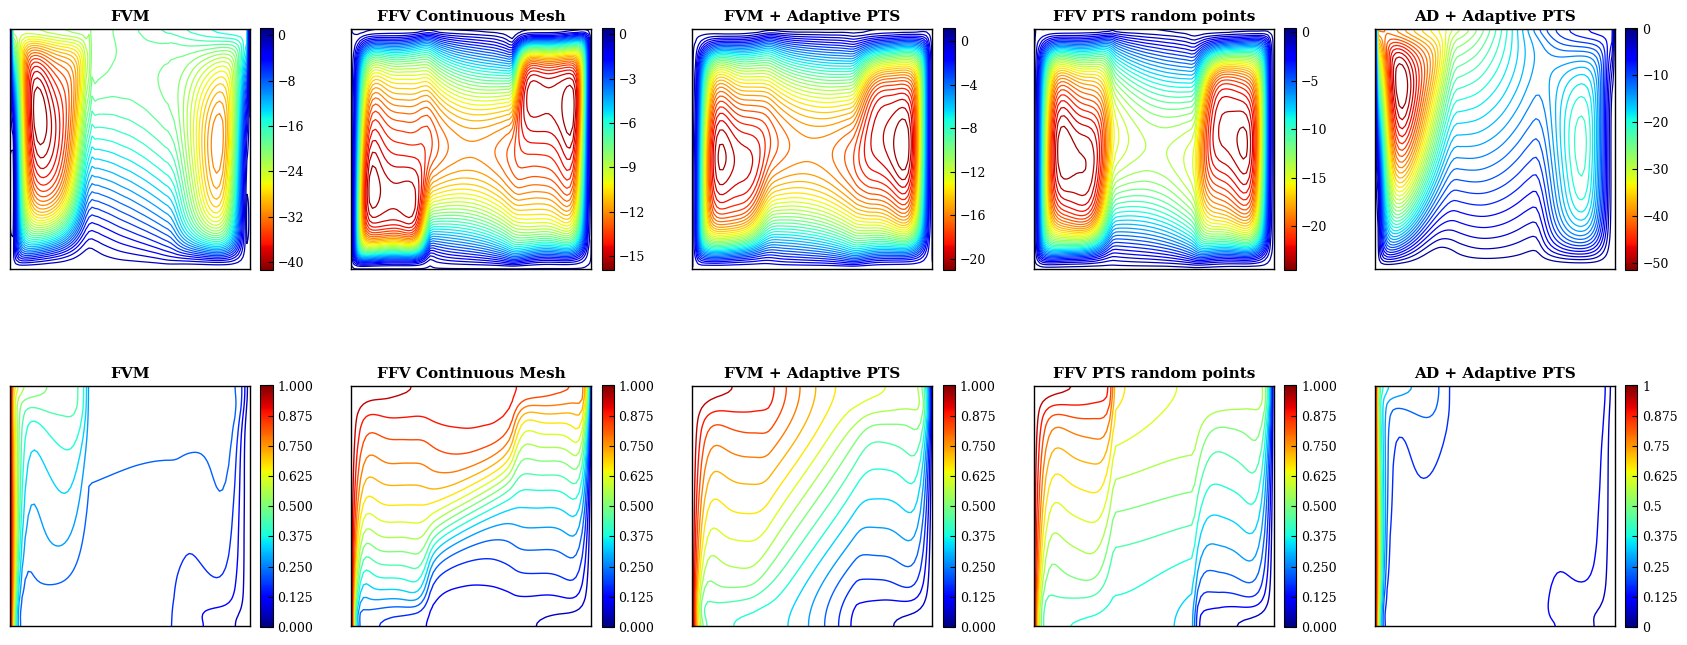

In [5]:
import matplotlib as mpl
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np

# Cấu hình thẩm mỹ theo tiêu chuẩn bài báo khoa học Elsevier
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif", "Liberation Serif"],
    "mathtext.fontset": "stix",
    "axes.linewidth": 1.0,
    "xtick.direction": "in",
    "ytick.direction": "in",
})

# =========================================================================
# TỰ ĐỘNG THÍCH ỨNG THEO SỐ LƯỢNG MODELS / TITLES TRUYỀN VÀO
# =========================================================================
n_models = len(titles)

# Tự co giãn chiều rộng figure theo số lượng model (khoảng 4.2 inch mỗi cột)
fig_width = max(4.2 * n_models, 8.0)
fig, axes = plt.subplots(2, n_models, figsize=(fig_width, 8.5), squeeze=False)

# 1. Định nghĩa thang đo Isotherms cố định chuẩn theo bài báo (Hình 7)
# Vạch hiển thị trên colorbar luôn cố định [0, 0.125, ..., 1.0]
t_cbar_ticks = np.linspace(0.0, 1.0, 9)

# Số lượng đường contour vẽ trên đồ thị (có thể tùy chỉnh độc lập mà không đổi thanh màu)
t_contour_levels = np.linspace(0.0, 1.0, 19)

cmap_T = plt.get_cmap("jet")
norm_T = mcolors.Normalize(vmin=0.0, vmax=1.0)

for i in range(n_models):
  # =======================================================================
  # 1. STREAMLINES (HÀNG TRÊN)
  # =======================================================================
  ax_psi = axes[0, i]

  psi_min = np.min(psi_list[i])
  psi_max = np.max(psi_list[i])

  # Mức contour đường dòng (tùy chọn mật độ đường, mặc định 40 mức)
  psi_contour_levels = np.linspace(psi_min, psi_max, 40)

  cmap_psi = plt.get_cmap("jet_r")
  norm_psi = mcolors.Normalize(vmin=psi_min, vmax=psi_max)

  # Vẽ các đường streamline
  ax_psi.contour(
      X,
      Y,
      psi_list[i],
      levels=psi_contour_levels,
      cmap=cmap_psi,
      norm=norm_psi,
      linewidths=0.9,
  )

  ax_psi.set_aspect("equal")
  ax_psi.set_title(f"{titles[i]}", fontsize=11, fontweight="bold")
  ax_psi.set_xticks([])
  ax_psi.set_yticks([])

  # Thanh màu Streamline: Dải màu liên tục, tự động chia mốc tròn số đẹp (5-6 mốc)
  sm_psi = cm.ScalarMappable(norm=norm_psi, cmap=cmap_psi)
  sm_psi.set_array([])
  cbar_psi = fig.colorbar(sm_psi, ax=ax_psi, fraction=0.046, pad=0.04)
  cbar_psi.locator = ticker.MaxNLocator(nbins=6, integer=True)
  cbar_psi.update_ticks()
  cbar_psi.ax.tick_params(labelsize=9)
  cbar_psi.outline.set_linewidth(0.8)

  # =======================================================================
  # 2. ISOTHERMS (HÀNG DƯỚI)
  # =======================================================================
  ax_T = axes[1, i]

  # Chuẩn hóa trường nhiệt độ về thang đo không thứ nguyên [0, 1]
  T_norm = (T_list[i] - np.min(T_list[i])) / (
      np.max(T_list[i]) - np.min(T_list[i]) + 1e-12
  )

  # Vẽ đường đẳng nhiệt theo mật độ t_contour_levels
  ax_T.contour(
      X,
      Y,
      T_norm,
      levels=t_contour_levels,
      cmap=cmap_T,
      norm=norm_T,
      linewidths=1.0,
  )

  ax_T.set_aspect("equal")
  ax_T.set_title(f"{titles[i]}", fontsize=11, fontweight="bold")
  ax_T.set_xticks([])
  ax_T.set_yticks([])

  # Thanh màu Isotherm: Cố định tuyệt đối theo mốc bài báo độc lập với contour levels
  sm_T = cm.ScalarMappable(norm=norm_T, cmap=cmap_T)
  sm_T.set_array([])
  cbar_T = fig.colorbar(
      sm_T, ax=ax_T, ticks=t_cbar_ticks, fraction=0.046, pad=0.04
  )
  cbar_T.ax.set_yticklabels([f"{val:.3g}" for val in t_cbar_ticks])
  cbar_T.ax.tick_params(labelsize=9)
  cbar_T.outline.set_linewidth(0.8)

plt.subplots_adjust(wspace=0.3, hspace=0.2)
plt.savefig("outputs/streamlines_isotherms_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

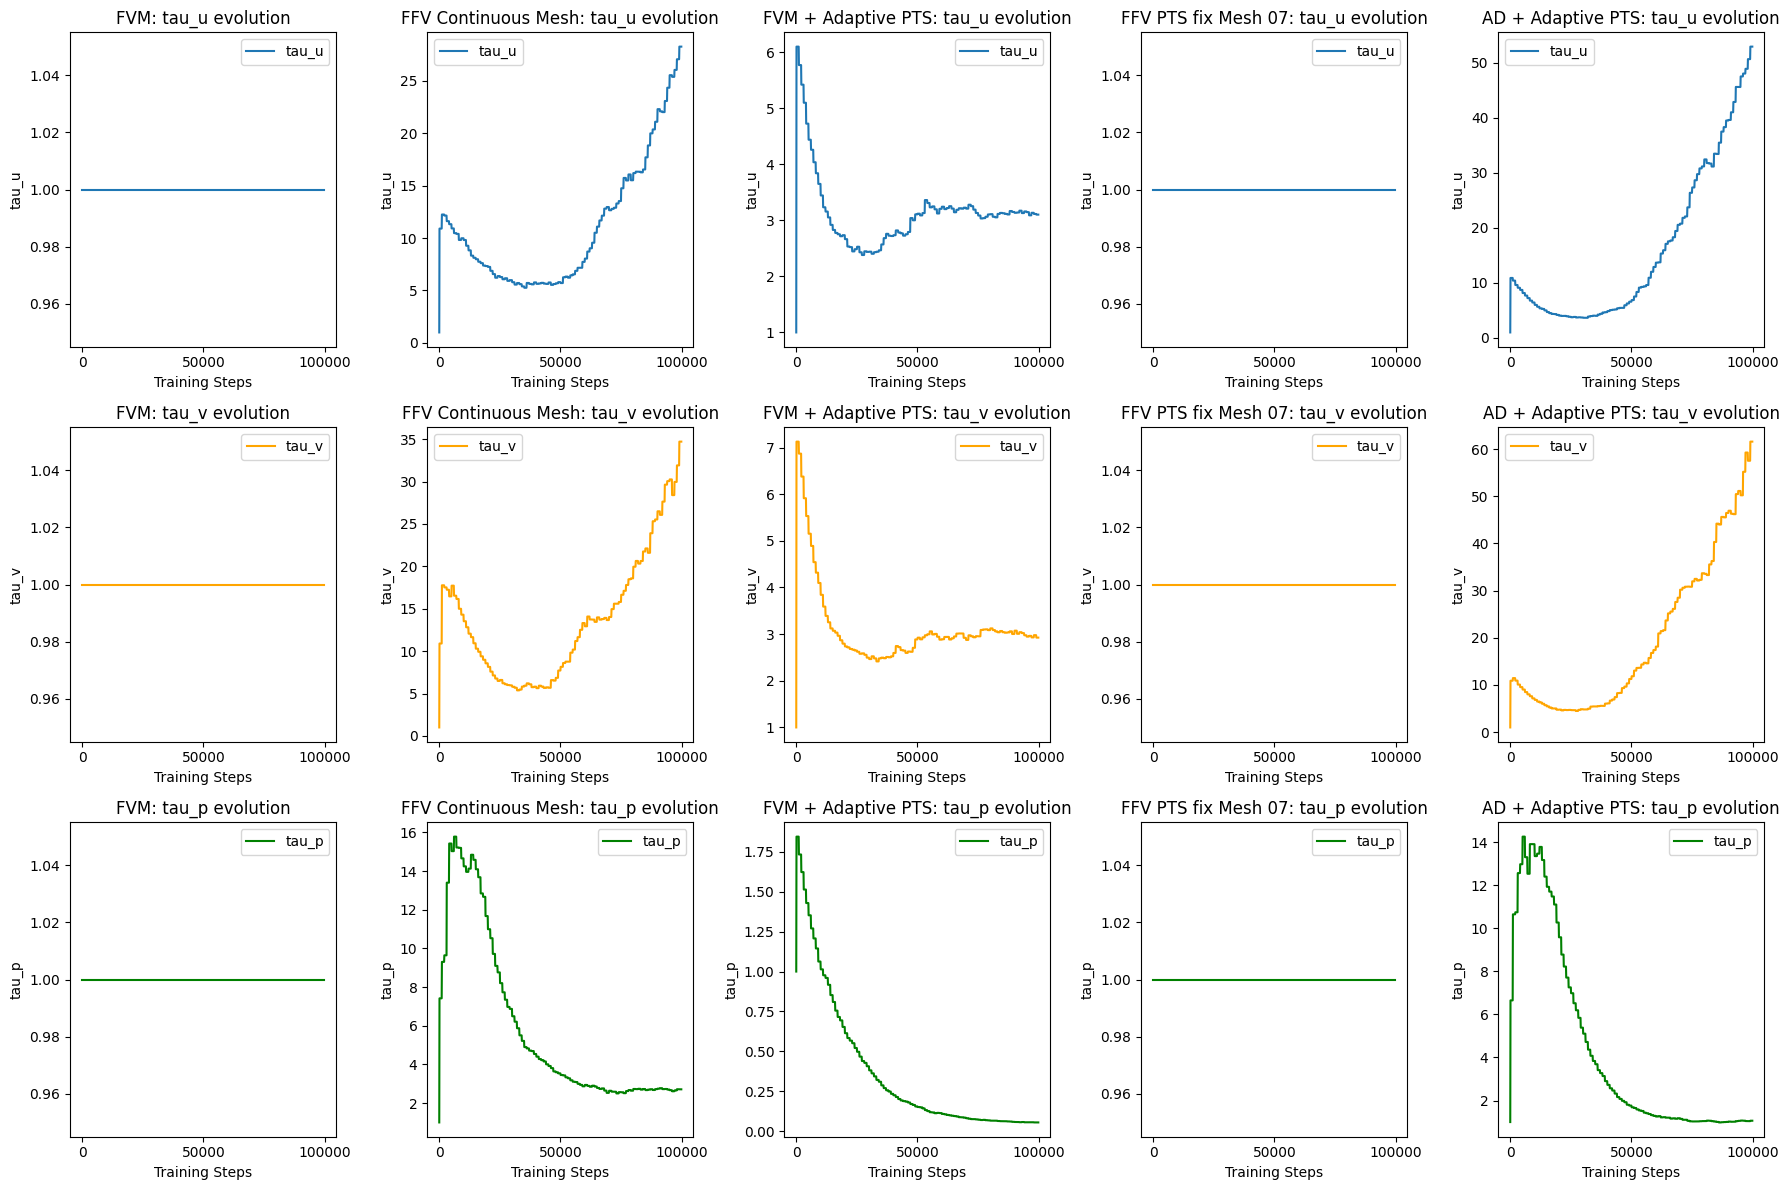

In [ ]:
tau_u_list = []
tau_v_list = []
tau_p_list = []
# fill in tau values for each model by evaluation histroy list 
for history in history_benchmark:
    tau_u = history.get("tau_u")
    tau_v = history.get("tau_v")
    tau_p = history.get("tau_p")
    tau_u_list.append(tau_u)
    tau_v_list.append(tau_v)
    tau_p_list.append(tau_p)

# plot 5 subplots for 5 models, each subplot contains 3 plots for tau_u, tau_v, tau_p evolution over training steps
plt.figure(figsize=(18, 12))
# because we saving 1 step per 1000 iteration, so we must fix the x axis to be 100 * len(tau_u_list[0])
iter = np.arange(0, 100 * len(tau_u_list[0]), 100)
for i in range(5):
    plt.subplot(3, 5, i + 1)
    plt.plot(iter,tau_u_list[i], label="tau_u")
    plt.title(f"{titles[i]}: tau_u evolution")
    plt.xlabel("Training Steps")
    plt.ylabel("tau_u")
    # x axis should  be only contain 0, 50000, 100000 
    plt.xticks([0, 50000, 100000])
    plt.legend()

    plt.subplot(3, 5, i + 6)
    plt.plot(iter,tau_v_list[i], label="tau_v", color="orange")
    plt.title(f"{titles[i]}: tau_v evolution")
    plt.xlabel("Training Steps")
    plt.ylabel("tau_v")
    plt.xticks([0, 50000, 100000])
    plt.legend()

    plt.subplot(3, 5, i + 11)
    plt.plot(iter,tau_p_list[i], label="tau_p", color="green")
    plt.title(f"{titles[i]}: tau_p evolution")
    plt.xlabel("Training Steps")
    plt.ylabel("tau_p")
    plt.xticks([0, 50000, 100000])
    plt.legend()
plt.tight_layout()
plt.show()


1074.7374267578125
883.4924926757812
1073.461669921875
1074.7374267578125
410.8212890625


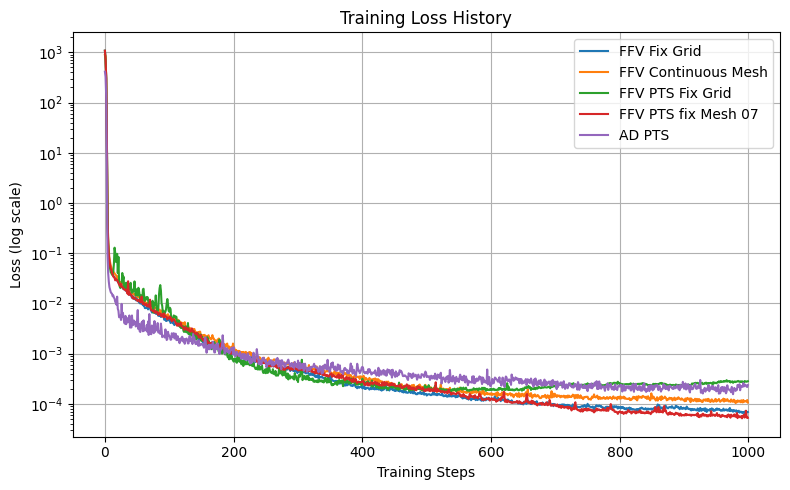

In [ ]:
import numpy as np 
# draw loss history
plt.figure(figsize=(8, 5))
for hist, label in zip(history_benchmark, titles):
    loss_values = hist.get("loss", [])
    print(loss_values[0])
    if loss_values:
        plt.plot(np.arange(len(loss_values)), loss_values, label=label)
plt.yscale("log")
plt.xlabel("Training Steps")
plt.ylabel("Loss (log scale)")
plt.title("Training Loss History")
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

In [ ]:
model_0, hist_0, _ = load_saved_model(exp_name="diff_ffv_case_2_soldiff13",org_config=aluminum)
model_1, hist_1, _ = load_saved_model(exp_name="diff_ffv_case_1_soldiff21",org_config=glass)
model_2, hist_2, _ = load_saved_model(exp_name="diff_ffv_case_2_soldiff20",org_config=aluminum) 
hist_list = [hist_0, hist_1, hist_2]
labels = ["sol_pressure", "sol_pressure_laplacian", "sol_uvp_laplacian"]

directory: /home/sonndt/Projects/FFV_PINN/nc_porous_layer/outputs/PorousNC_layer_diff_ffv_case_2_soldiff13/ckpt
-> Đã nạp thành công checkpoint tại step 100000
-> Đã nạp lịch sử huấn luyện: 1000 bước log
directory: /home/sonndt/Projects/FFV_PINN/nc_porous_layer/outputs/PorousNC_layer_diff_ffv_case_1_soldiff21/ckpt
-> Đã nạp thành công checkpoint tại step 50000
-> Đã nạp lịch sử huấn luyện: 500 bước log
directory: /home/sonndt/Projects/FFV_PINN/nc_porous_layer/outputs/PorousNC_layer_diff_ffv_case_2_soldiff20/ckpt
-> Đã nạp thành công checkpoint tại step 100000
-> Đã nạp lịch sử huấn luyện: 1000 bước log


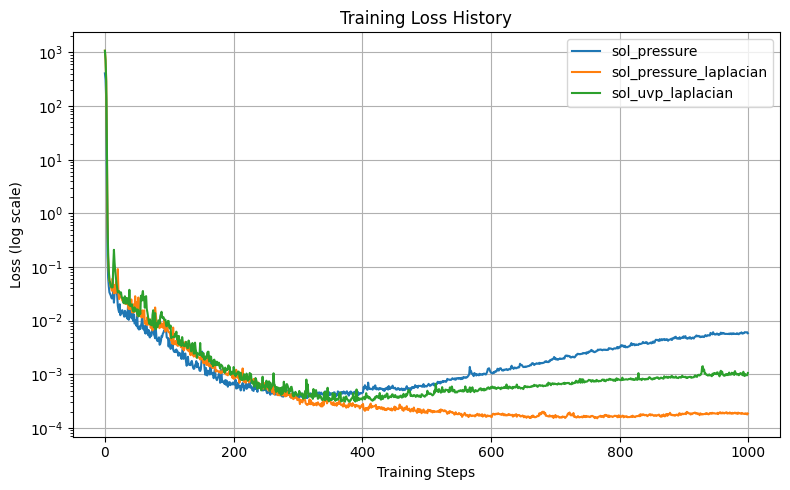

In [ ]:
import numpy as np 
# draw loss history
plt.figure(figsize=(8, 5))
for hist, label in zip(hist_list, labels):
    loss_values = hist.get("loss", [])
    if loss_values:
        plt.plot(np.arange(len(loss_values)), loss_values, label=label)
plt.yscale("log")
plt.xlabel("Training Steps")
plt.ylabel("Loss (log scale)")
plt.title("Training Loss History")
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

<>:27: SyntaxWarning: "\i" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\i"? A raw string is also an option.
<>:27: SyntaxWarning: "\i" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\i"? A raw string is also an option.
/tmp/ipykernel_7892/1968052176.py:27: SyntaxWarning: "\i" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\i"? A raw string is also an option.
  psi^*(x, y) = sqrt(Ra * Pr) * \int_0^y u(x, y') dy'



Calculated Maximum Stream Function (|psi|_max): 26.3456
Benchmark Case 1 Reference: ~16.52 - 16.77 (Table 5)

Calculated Maximum Stream Function (|psi|_max): 17.6158
Benchmark Case 1 Reference: ~16.52 - 16.77 (Table 5)

Calculated Maximum Stream Function (|psi|_max): 25.4903
Benchmark Case 1 Reference: ~16.52 - 16.77 (Table 5)


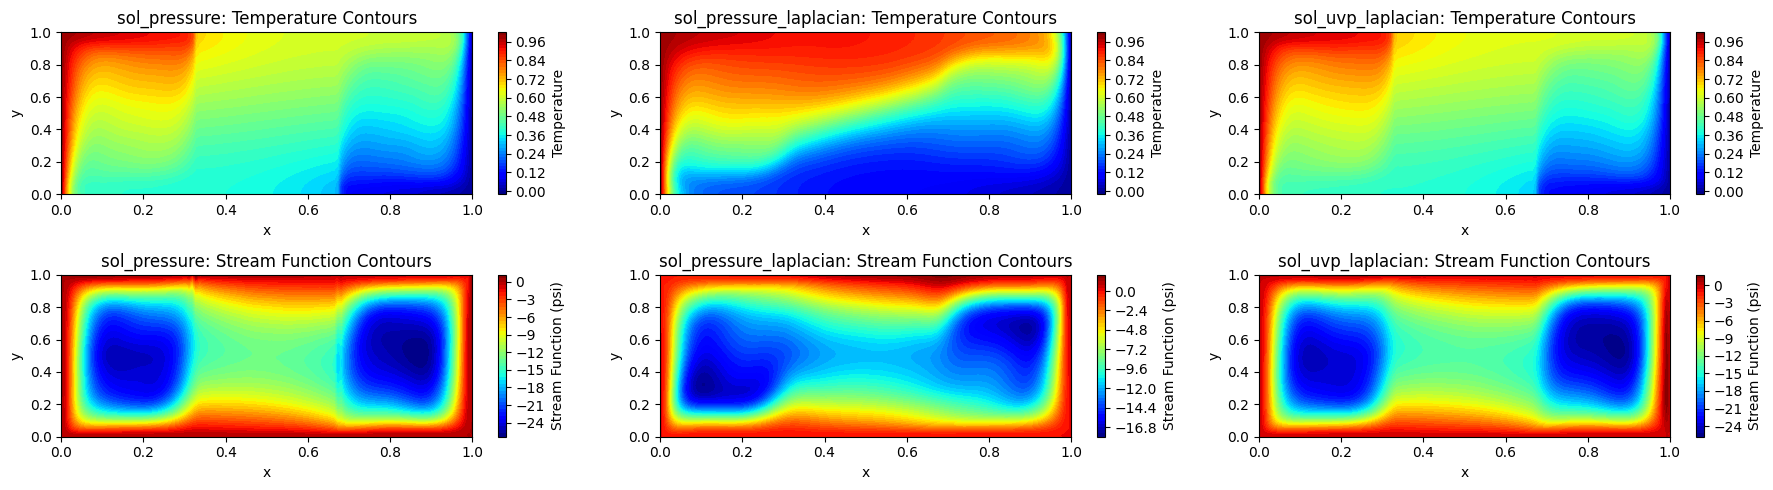

In [ ]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

# 1. Tạo lưới đều 120x120 (khớp độ phân giải 120x120 của bài báo)
Nx, Ny = 120, 120
x_lin = jnp.linspace(0.0, 1.0, Nx)
y_lin = jnp.linspace(0.0, 1.0, Ny)
X, Y = jnp.meshgrid(x_lin, y_lin)
x_flat, y_flat = X.ravel(), Y.ravel()

def evaluate_fields(model):
  u, v, p, T = jax.vmap(model.neural_net, (None, 0, 0))(
      model.state.params, x_flat, y_flat
  )
  return (
      np.array(u).reshape(Ny, Nx),
      np.array(v).reshape(Ny, Nx),
      np.array(p).reshape(Ny, Nx),
      np.array(T).reshape(Ny, Nx),
  )

def compute_stream_function_and_psimax(U_grid, model_config, ny=120, H=1.0):
  """
  Tính trường hàm dòng psi(x, y) chuẩn hóa theo alpha_m (khớp với Table 5).
  psi^*(x, y) = sqrt(Ra * Pr) * \int_0^y u(x, y') dy'
  """
  dy = H / (ny - 1)

  # Tích phân số theo trục y (axis 0)
  psi_grid = np.zeros_like(U_grid)
  for j in range(1, ny):
    psi_grid[j, :] = psi_grid[j - 1, :] + 0.5 * (U_grid[j, :] + U_grid[j - 1, :]) * dy

  # Hệ số chuyển đổi sang hệ chuẩn hóa của bài báo
  Ra = model_config.physics.get("Ra", 3.7e6)
  Pr = model_config.physics.get("Pr", 6.44)
  scale_factor = np.sqrt(Ra * Pr)

  # Chuẩn hóa về thang đo benchmark
  psi_grid_scaled = psi_grid * scale_factor
  psi_max = np.max(np.abs(psi_grid_scaled))

  print("\n" + "=" * 50)
  print(f"Calculated Maximum Stream Function (|psi|_max): {psi_max:.4f}")
  print("Benchmark Case 1 Reference: ~16.52 - 16.77 (Table 5)")
  print("=" * 50)
  return psi_max, psi_grid_scaled

# 2. Đánh giá trường nghiệm


u_list, v_list, p_list, T_list = [], [], [], []
vel_mag_list, psi_list, psi_max_list = [], [], []
for model in [model_0, model_1, model_2]:
    u, v, p, T = evaluate_fields(model)
    u_list.append(u)
    v_list.append(v)
    p_list.append(p)
    T_list.append(T)
    vel_mag = np.sqrt(u**2 + v**2)
    vel_mag_list.append(vel_mag)
    psi_max, psi = compute_stream_function_and_psimax(u, model.config, ny=Ny, H=1.0)
    psi_list.append(psi)
    psi_max_list.append(psi_max)

# plot temperature contours and stream function contours
plt.figure(figsize=(18, 5))
titles = labels
for i in range(3):
    plt.subplot(2, 3, i + 1)
    plt.contourf(X, Y, T_list[i], levels=50, cmap="jet")
    plt.colorbar(label="Temperature")
    plt.title(f"{titles[i]}: Temperature Contours")
    plt.xlabel("x")
    plt.ylabel("y")

    plt.subplot(2, 3, i + 4)
    plt.contourf(X, Y, psi_list[i], levels=50, cmap="jet")
    plt.colorbar(label="Stream Function (psi)")
    plt.title(f"{titles[i]}: Stream Function Contours")
    plt.xlabel("x")
    plt.ylabel("y")

plt.tight_layout()
plt.show()

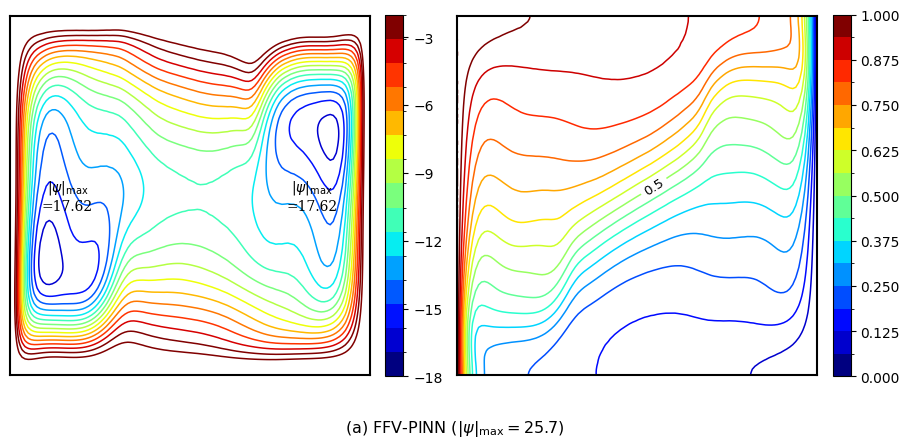

--> Đã lưu biểu đồ chuẩn Elsevier tại: ffv_pinn_isolines_elsevier.pdf


In [ ]:
import matplotlib.cm as cm
from matplotlib.colors import BoundaryNorm
import matplotlib.pyplot as plt
import numpy as np


def plot_elsevier_isolines(
    X,
    Y,
    psi_grid,
    T_grid,
    psi_max,
    case_label='(a) Model Prediction',
    save_path='streamlines_isotherms_elsevier.png',
):
  """Vẽ Streamlines và Isotherms theo chuẩn bài báo Gao et al. (2017)."""
  fig, axes = plt.subplots(1, 2, figsize=(9.2, 4.3))

  # =========================================================================
  # 1. STREAM FUNCTION CONTOURS (CỘT TRÁI)
  # =========================================================================
  ax_psi = axes[0]

  # Mức đường đẳng trị cho Stream Function
  psi_min_val = np.floor(np.min(psi_grid) / 2.0) * 2.0
  levels_psi = np.linspace(psi_min_val, -2.0, 16)
  norm_psi = BoundaryNorm(levels_psi, ncolors=cm.jet.N, clip=True)

  # Vẽ các đường contour hàm dòng
  cs_psi = ax_psi.contour(
      X,
      Y,
      psi_grid,
      levels=levels_psi,
      cmap='jet',
      norm=norm_psi,
      linewidths=1.1,
  )

  # Colorbar rời rạc chuẩn format Gao et al.
  tick_step = 3.0 if abs(psi_min_val) > 15 else 2.0
  cbar_ticks = np.arange(psi_min_val, 0.0, tick_step)
  cbar_psi = fig.colorbar(
      cm.ScalarMappable(norm=norm_psi, cmap='jet'),
      ax=ax_psi,
      fraction=0.046,
      pad=0.04,
      ticks=cbar_ticks,
  )
  cbar_psi.ax.tick_params(labelsize=10, direction='out')

  # ĐÃ SỬA LỖI: Tách ký tự \n ra ngoài môi trường toán $...$
  label_text = rf'$|\psi|_{{\max}}$' + f'\n={psi_max:.2f}'

  ax_psi.text(
      0.16,
      0.50,
      label_text,
      ha='center',
      va='center',
      fontsize=10,
      fontfamily='serif',
  )
  ax_psi.text(
      0.84,
      0.50,
      label_text,
      ha='center',
      va='center',
      fontsize=10,
      fontfamily='serif',
  )

  # Khung hình vuông tỉ lệ 1:1, ẩn tick tọa độ, viền đậm
  ax_psi.set_aspect('equal')
  ax_psi.set_xlim([0.0, 1.0])
  ax_psi.set_ylim([0.0, 1.0])
  ax_psi.set_xticks([])
  ax_psi.set_yticks([])
  for spine in ax_psi.spines.values():
    spine.set_linewidth(1.5)

  # =========================================================================
  # 2. TEMPERATURE CONTOURS (ISOTHERMS - CỘT PHẢI)
  # =========================================================================
  ax_T = axes[1]

  # Mức đường đẳng nhiệt từ 0.0 đến 1.0
  levels_T = np.linspace(0.0, 1.0, 17)
  norm_T = BoundaryNorm(levels_T, ncolors=cm.jet.N, clip=True)

  # Vẽ các đường contour nhiệt độ
  cs_T = ax_T.contour(
      X, Y, T_grid, levels=levels_T, cmap='jet', norm=norm_T, linewidths=1.1
  )

  # Gán nhãn 0.5 lên đường đẳng nhiệt trung tâm
  ax_T.clabel(
      cs_T,
      levels=[0.5],
      inline=True,
      fontsize=9.5,
      fmt='0.5',
      colors='black',
      inline_spacing=3,
  )

  # Colorbar rời rạc chuẩn 8 vạch chia từ 0 đến 1
  cbar_T = fig.colorbar(
      cm.ScalarMappable(norm=norm_T, cmap='jet'),
      ax=ax_T,
      fraction=0.046,
      pad=0.04,
      ticks=np.linspace(0.0, 1.0, 9),
  )
  cbar_T.ax.tick_params(labelsize=10, direction='out')

  # Khung hình vuông
  ax_T.set_aspect('equal')
  ax_T.set_xlim([0.0, 1.0])
  ax_T.set_ylim([0.0, 1.0])
  ax_T.set_xticks([])
  ax_T.set_yticks([])
  for spine in ax_T.spines.values():
    spine.set_linewidth(1.5)

  # Ghi chú nhãn bên dưới ảnh
  fig.text(0.5, -0.05, case_label, ha='center', fontsize=11.5)

  plt.tight_layout()
  # add transparent background to the saved figure, adn save as pdf
  plt.savefig(save_path, dpi=300, bbox_inches='tight', transparent=True)
  #plt.savefig(save_path, dpi=300, bbox_inches='tight', transparent=True)
  #plt.savefig(save_path, dpi=300, bbox_inches='tight')
  plt.show()
  print(f'--> Đã lưu biểu đồ chuẩn Elsevier tại: {save_path}')

plot_elsevier_isolines(
    X, Y,
    psi_grid=psi_list[1],
    T_grid=T_list[1],
    psi_max=psi_max_list[1],
    case_label=r"(a) FFV-PINN ($|\psi|_{\max} = 25.7$)",
    save_path="ffv_pinn_isolines_elsevier.pdf"
)